# TV5 – So sánh nhóm phim và phân tích sai lệch

Dùng `movie_summary.csv` và `movie_data.csv` trong thư mục dữ liệu sạch của nhóm. Ngưỡng chính theo đề xuất TV3: `rating_count >= 20`; phim điểm cao: `average_rating >= 4.0`.

## Ghi chú kiểm tra dữ liệu (28/10/2026)

Notebook được cấu hình ưu tiên đọc dữ liệu từ thư mục `../0.2_Du_lieu_sach/` khi chạy từ thư mục `0.3_Code_Python`. Hai tệp đã kiểm tra có 9.724 phim trong `movie_summary.csv` và 100.836 dòng trong `movie_data.csv`. Cell kiểm tra dữ liệu bên dưới xác nhận tổng `rating_count` bằng số dòng rating và số lượt theo từng `movieId` khớp. Các cell đã được chạy lại thành công trên đúng cấu trúc thư mục này.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(".")
if not (DATA_DIR / "movie_summary.csv").exists():
    if (Path("../0.2_Du_lieu_sach") / "movie_summary.csv").exists():
        DATA_DIR = Path("../0.2_Du_lieu_sach")
    elif (Path("../Du_lieu_can_de_chay_code") / "movie_summary.csv").exists():
        DATA_DIR = Path("../Du_lieu_can_de_chay_code")
    else:
        raise FileNotFoundError("Khong tim thay movie_summary.csv va movie_data.csv. Hay dat hai file trong 0.2_Du_lieu_sach hoac cung thu muc voi notebook.")
movies = pd.read_csv(DATA_DIR / "movie_summary.csv")
ratings = pd.read_csv(DATA_DIR / "movie_data.csv")
THRESHOLD = 20
HIGH_RATING = 4.0
print("movie_summary:", movies.shape, "| movie_data:", ratings.shape)
display(movies.head())

movie_summary: (9724, 5) | movie_data: (100836, 7)


,movieId,title,genres,rating_count,average_rating
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.16
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.43
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.16
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.19


## 1. Kiểm tra tính nhất quán của hai tệp

In [2]:
counts = ratings.groupby("movieId").size()
count_match = (counts.reindex(movies.movieId).fillna(0).astype(int).to_numpy()
               == movies.rating_count.astype(int).to_numpy()).all()
print("Tổng rating_count:", int(movies.rating_count.sum()))
print("Số dòng movie_data:", len(ratings))
print("Số lượt theo movieId khớp:", count_match)
display(movies[["rating_count", "average_rating"]].describe())

Tổng rating_count: 100836
Số dòng movie_data: 100836
Số lượt theo movieId khớp: True


,rating_count,average_rating
count,9724.000000,9724.000000
mean,10.369807,3.262465
std,22.401005,0.869896
min,1.000000,0.500000
25%,1.000000,2.800000
50%,3.000000,3.420000
75%,9.000000,3.910000
max,329.000000,5.000000


## 2. So sánh ba nhóm phim

In [3]:
group_A = movies.sort_values(["rating_count","average_rating"], ascending=[False,False]).head(10)
group_B_all = movies[(movies.average_rating >= HIGH_RATING) & (movies.rating_count < THRESHOLD)]
group_B = group_B_all.sort_values(["average_rating","rating_count"], ascending=[False,True]).head(10)
group_C_all = movies[(movies.average_rating >= HIGH_RATING) & (movies.rating_count >= THRESHOLD)]
group_C = group_C_all.sort_values(["average_rating","rating_count"], ascending=[False,False]).head(10)
for name, frame in [("A - Top 10 phổ biến", group_A), ("B - Điểm cao, dưới ngưỡng (10 ví dụ)", group_B), ("C - Điểm cao, đạt ngưỡng (10 phim)", group_C)]:
    print("\\n", name)
    display(frame[["title","rating_count","average_rating"]])
print("Số phim nhóm B:", len(group_B_all))
print("Số phim nhóm C:", len(group_C_all))

\n A - Top 10 phổ biến


,title,rating_count,average_rating
0,Forrest Gump (1994),329,4.16
1,"Shawshank Redemption, The (1994)",317,4.43
2,Pulp Fiction (1994),307,4.20
3,"Silence of the Lambs, The (1991)",279,4.16
4,"Matrix, The (1999)",278,4.19
5,Star Wars: Episode IV - A New Hope (1977),251,4.23
6,Jurassic Park (1993),238,3.75
7,Braveheart (1995),237,4.03
8,Terminator 2: Judgment Day (1991),224,3.97
9,Schindler's List (1993),220,4.22


\n B - Điểm cao, dưới ngưỡng (10 ví dụ)


,title,rating_count,average_rating
6278,"Awfully Big Adventure, An (1995)",1,5.0
6279,Live Nude Girls (1995),1,5.0
6280,In the Realm of the Senses (Ai no corrida) (1976),1,5.0
6281,What Happened Was... (1994),1,5.0
6282,"Thin Line Between Love and Hate, A (1996)",1,5.0
6283,Denise Calls Up (1995),1,5.0
6284,Supercop 2 (Project S) (Chao ji ji hua) (1993),1,5.0
6285,Entertaining Angels: The Dorothy Day Story (1996),1,5.0
6286,Hype! (1996),1,5.0
6287,Vampire in Venice (Nosferatu a Venezia) (Nosfe...,1,5.0


\n C - Điểm cao, đạt ngưỡng (10 phim)


,title,rating_count,average_rating
1235,"Streetcar Named Desire, A (1951)",20,4.47
1,"Shawshank Redemption, The (1994)",317,4.43
933,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),27,4.33
882,"Philadelphia Story, The (1940)",29,4.31
507,Lawrence of Arabia (1962),45,4.30
1012,In the Name of the Father (1993),25,4.30
21,"Godfather, The (1972)",192,4.29
883,Hoop Dreams (1994),29,4.29
976,Harold and Maude (1971),26,4.29
1013,Logan (2017),25,4.28


Số phim nhóm B: 2107
Số phim nhóm C: 164


## 3. Xếp hạng trước và sau ngưỡng 20

In [4]:
top_before = movies.sort_values(["average_rating","rating_count"], ascending=[False,False]).head(10)
top_after = movies[movies.rating_count >= THRESHOLD].sort_values(["average_rating","rating_count"], ascending=[False,False]).head(10)
print("Top 10 trước ngưỡng"); display(top_before[["title","rating_count","average_rating"]])
print("Top 10 sau ngưỡng 20"); display(top_after[["title","rating_count","average_rating"]])

Top 10 trước ngưỡng


,title,rating_count,average_rating
4980,Lamerica (1994),2,5.0
4981,Heidi Fleiss: Hollywood Madam (1995),2,5.0
4982,Lesson Faust (1994),2,5.0
4983,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,2,5.0
4984,Belle époque (1992),2,5.0
4985,Come and See (Idi i smotri) (1985),2,5.0
4986,Enter the Void (2009),2,5.0
6278,"Awfully Big Adventure, An (1995)",1,5.0
6279,Live Nude Girls (1995),1,5.0
6280,In the Realm of the Senses (Ai no corrida) (1976),1,5.0


Top 10 sau ngưỡng 20


,title,rating_count,average_rating
1235,"Streetcar Named Desire, A (1951)",20,4.47
1,"Shawshank Redemption, The (1994)",317,4.43
933,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),27,4.33
882,"Philadelphia Story, The (1940)",29,4.31
507,Lawrence of Arabia (1962),45,4.30
1012,In the Name of the Father (1993),25,4.30
21,"Godfather, The (1972)",192,4.29
883,Hoop Dreams (1994),29,4.29
976,Harold and Maude (1971),26,4.29
1013,Logan (2017),25,4.28


## 4. Tương quan toàn bộ và sau ngưỡng

In [5]:
eligible = movies[movies.rating_count >= THRESHOLD]
print("Pearson toàn bộ:", movies.rating_count.corr(movies.average_rating))
print("Spearman toàn bộ:", movies.rating_count.corr(movies.average_rating, method="spearman"))
print("Pearson sau ngưỡng:", eligible.rating_count.corr(eligible.average_rating))
print("Spearman sau ngưỡng:", eligible.rating_count.corr(eligible.average_rating, method="spearman"))
print("Phim còn lại:", len(eligible), f"({len(eligible)/len(movies):.2%})")

Pearson toàn bộ: 0.1272824251528481


Spearman toàn bộ: 0.039692599654123285
Pearson sau ngưỡng: 0.30348120805330375
Spearman sau ngưỡng: 0.2656861260082574
Phim còn lại: 1297 (13.34%)


## 5. Biểu đồ phân tán

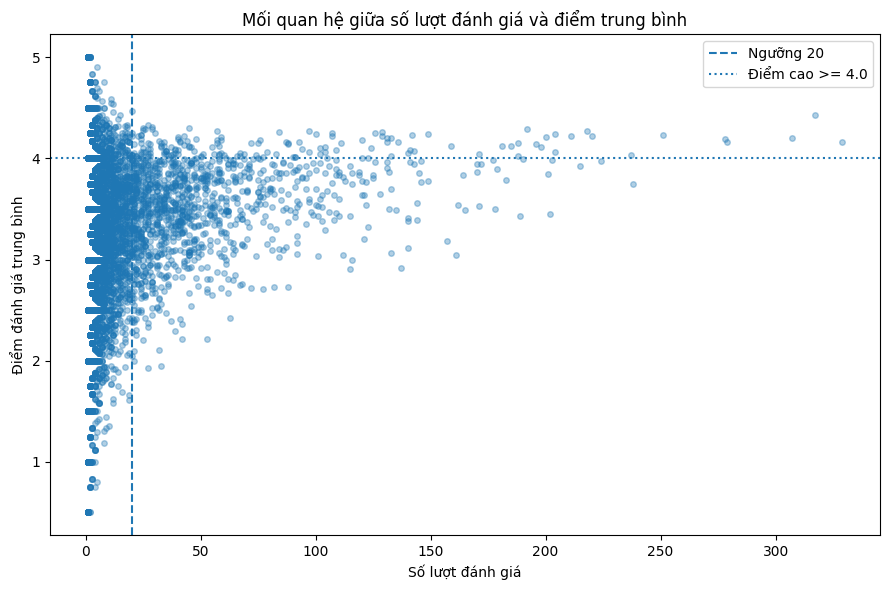

In [6]:
plt.figure(figsize=(9,6))
plt.scatter(movies.rating_count, movies.average_rating, alpha=.35, s=16)
plt.axvline(THRESHOLD, linestyle="--", label=f"Ngưỡng {THRESHOLD}")
plt.axhline(HIGH_RATING, linestyle=":", label=f"Điểm cao >= {HIGH_RATING}")
plt.xlabel("Số lượt đánh giá"); plt.ylabel("Điểm đánh giá trung bình")
plt.title("Mối quan hệ giữa số lượt đánh giá và điểm trung bình")
plt.legend(); plt.tight_layout(); plt.show()

## 6. So sánh điểm trung bình và số lượt theo nhóm

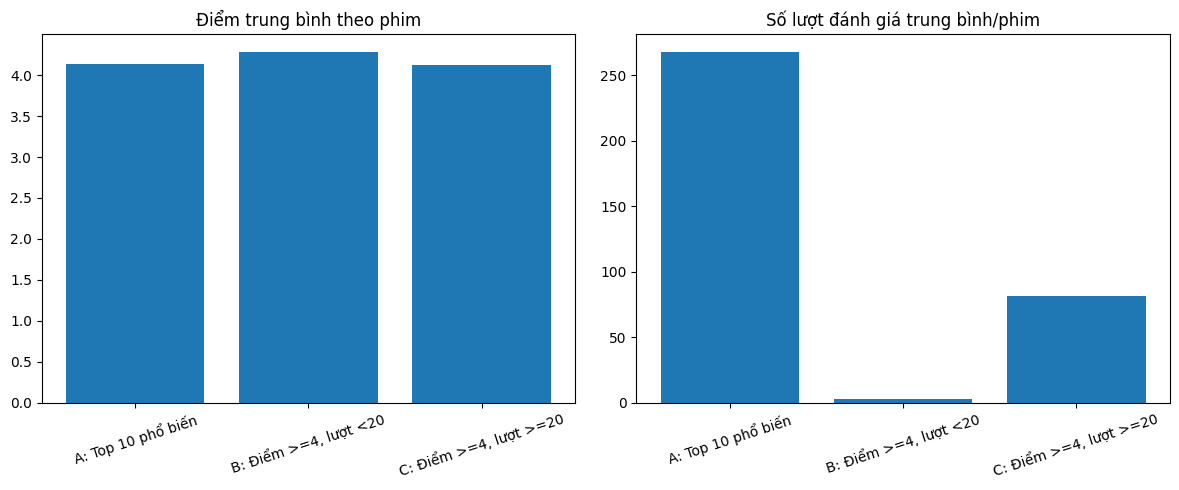

In [7]:
groups = [("A: Top 10 phổ biến", group_A), ("B: Điểm >=4, lượt <20", group_B_all), ("C: Điểm >=4, lượt >=20", group_C_all)]
labels = [g[0] for g in groups]
mean_scores = [g[1].average_rating.mean() if len(g[1]) else 0 for g in groups]
mean_counts = [g[1].rating_count.mean() if len(g[1]) else 0 for g in groups]
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].bar(labels,mean_scores); axes[0].set_title("Điểm trung bình theo phim"); axes[0].tick_params(axis="x",rotation=18)
axes[1].bar(labels,mean_counts); axes[1].set_title("Số lượt đánh giá trung bình/phim"); axes[1].tick_params(axis="x",rotation=18)
plt.tight_layout(); plt.show()

## 7. Diễn giải và giới hạn

Điểm trung bình của phim ít lượt đánh giá có thể thiếu ổn định vì mỗi lượt rating có ảnh hưởng lớn. `rating_count` là chỉ báo thay thế cho mức độ phổ biến trong tập dữ liệu, không đồng nghĩa với lượt xem hoặc doanh thu. Ngưỡng 20 theo đề xuất TV3 là lựa chọn phân tích, không loại bỏ thiên lệch tự chọn và không chứng minh quan hệ nhân quả.